# EDA e preparação de queries para busca no YouTube: recorte `mercado`

Este notebook analisa o catálogo consolidado de notícias, mas trabalha apenas com registros em que `catalogacao_final == "mercado"`. Itens rotulados como `outros` são descartados logo no início, assim como duplicatas remanescentes.

Objetivos:
- medir se `title` é um bom parâmetro de busca dentro do recorte `mercado`;
- construir campos-semente úteis para record-linkage;
- gerar um `news_query_manifest` vinculado a `record_id`;
- manter o uso futuro do `YouTubeDataClient` compatível com o projeto atual.


## Premissas e conclusão esperada

O notebook filtra o dataset para manter apenas `catalogacao_final == "mercado"` e descarta duplicatas usando `duplicate_group_rank_analysis_text`, `record_id` e `analysis_text` como salvaguardas operacionais.

A decisão operacional continua a mesma dentro desse recorte: `title` vira o sinal primário quando estiver limpo e forte, mas as consultas preparadas também combinam lead textual, entidades e janela temporal para dar suporte ao record-linkage depois.


In [1]:
from __future__ import annotations

from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from youtube_data_pipeline.query_preparation import (
    normalize_text,
    prepare_news_query_data,
    strip_publisher_suffix,
    strip_title_prefix,
    write_prepared_artifacts,
)

sns.set_theme(style='whitegrid')
pd.set_option('display.max_colwidth', 160)

DATA_PATH = Path('../data/raw/compiled_full_catalogado_final_sem_duplicatas_por_analysis_text.jsonl').resolve()
OUTPUT_DIR = Path('../data/processed/news_query_preparation_market_only').resolve()
CHUNK_SIZE = 2_000
TARGET_LABEL = 'mercado'

print(DATA_PATH)
print(OUTPUT_DIR)


data/raw/compiled_full_catalogado_final_sem_duplicatas_por_analysis_text.jsonl
data/processed/news_query_preparation_market_only


## 1. Normalização, recorte `mercado` e descarte de duplicatas

A análise começa com a leitura do catálogo consolidado, normalização de campos textuais, filtro para `catalogacao_final == "mercado"` e descarte explícito de duplicatas antes de qualquer métrica de cobertura.


In [2]:
for i in pd.read_json(DATA_PATH, lines=True, chunksize=CHUNK_SIZE):
    break

i.columns

Index(['record_id', 'dataset_id', 'analysis_text', 'claim_text', 'source_url',
       'bert_label', 'bert_confidence', 'bert_score_mercado', 'heuristic_band',
       'heuristic_score', 'review_bucket', 'review_score', 'selection_reason',
       'global_review_rank', 'openai_model', 'openai_prompt_version',
       'openai_label', 'openai_confidence', 'openai_score_mercado',
       'openai_score_outros', 'openai_rationale', 'openai_reviewed',
       'catalogacao_final', 'catalogacao_final_source',
       'catalogacao_final_confidence', 'title', 'subtitle', 'author',
       'body_text', 'category', 'language', 'published_at', 'original_label',
       'standard_label', 'text_for_ner', 'text_without_stopwords',
       'lemmatized_text', 'entities', 'metadata', 'source_domain_display',
       'veracidade_binaria', 'veracidade_original', 'entity_count',
       'has_source_url', 'analysis_text_len',
       'duplicate_group_size_analysis_text',
       'duplicate_group_rank_analysis_text',
     

In [3]:
TEXT_COLUMNS = [
    'record_id',
    'dataset_id',
    'title',
    'subtitle',
    'claim_text',
    'analysis_text',
    'body_text',
    'published_at',
    'source_url',
    'source_domain_display',
    'language',
    'catalogacao_final',
    'veracidade_binaria',
]

raw_df = pd.read_json(DATA_PATH, lines=True)

for column in TEXT_COLUMNS:
    if column not in raw_df.columns:
        raw_df[column] = ''
    raw_df[column] = raw_df[column].map(normalize_text)

raw_df['source_domain'] = raw_df['source_domain_display']
raw_df['source_domain'] = raw_df['source_domain'].replace('', pd.NA)
if 'metadata' in raw_df.columns:
    raw_df['source_domain'] = raw_df.apply(
        lambda row: row['source_domain']
        if pd.notna(row['source_domain'])
        else normalize_text((row.get('metadata') or {}).get('source_domain')),
        axis=1,
    )
else:
    raw_df['source_domain'] = ''

raw_df['has_entities'] = raw_df['entities'].map(lambda value: isinstance(value, list) and len(value) > 0)
raw_df['entity_count_clean'] = pd.to_numeric(raw_df.get('entity_count', 0), errors='coerce').fillna(0).astype(int)
raw_df['duplicate_rank'] = pd.to_numeric(
    raw_df.get('duplicate_group_rank_analysis_text', pd.Series(index=raw_df.index, dtype='float64')),
    errors='coerce',
)

rows_total = len(raw_df)
market_df = raw_df.loc[raw_df['catalogacao_final'].eq(TARGET_LABEL)].copy()
rows_after_label_filter = len(market_df)
market_df = market_df.loc[market_df['duplicate_rank'].isna() | market_df['duplicate_rank'].eq(1)].copy()
rows_after_duplicate_rank = len(market_df)
market_df = market_df.drop_duplicates(subset=['record_id'], keep='first')
market_df = market_df.drop_duplicates(subset=['analysis_text'], keep='first')
filtered_df = market_df.reset_index(drop=True)
rows_after_full_filter = len(filtered_df)

coverage_counter = Counter()
coverage_rows = []
title_examples_missing = []
prefix_counter = Counter()
suffix_counter = Counter()
title_frequency = Counter()
domain_counter = Counter()
entity_count_values = []

for _, row in filtered_df.iterrows():
    coverage_counter['rows'] += 1
    coverage_counter['title_present'] += int(bool(row['title']))
    coverage_counter['subtitle_present'] += int(bool(row['subtitle']))
    coverage_counter['claim_present'] += int(bool(row['claim_text']))
    coverage_counter['analysis_present'] += int(bool(row['analysis_text']))
    coverage_counter['body_present'] += int(bool(row['body_text']))
    coverage_counter['published_at_present'] += int(bool(row['published_at']))
    coverage_counter['source_url_present'] += int(bool(row['source_url']))
    coverage_counter['source_domain_present'] += int(bool(row['source_domain']))
    coverage_counter['entities_present'] += int(bool(row['has_entities']))

    if row['title']:
        title_frequency[row['title']] += 1
        prefix_clean, had_prefix = strip_title_prefix(row['title'])
        _, had_suffix = strip_publisher_suffix(
            prefix_clean,
            source_url=row['source_url'],
            source_domain=row['source_domain'],
        )
        if had_prefix:
            prefix_counter[row['title'].split(' ', 3)[0].lower()] += 1
        if had_suffix:
            suffix_counter[row['source_domain'] or 'unknown'] += 1
    elif len(title_examples_missing) < 10:
        title_examples_missing.append({
            'record_id': row['record_id'],
            'dataset_id': row['dataset_id'],
            'source_domain': row['source_domain'],
            'analysis_preview': row['analysis_text'][:140],
        })

    if row['source_domain']:
        domain_counter[row['source_domain']] += 1
    entity_count_values.append(row['entity_count_clean'])

for field, key in [
    ('title', 'title_present'),
    ('subtitle', 'subtitle_present'),
    ('claim_text', 'claim_present'),
    ('analysis_text', 'analysis_present'),
    ('body_text', 'body_present'),
    ('published_at', 'published_at_present'),
    ('source_url', 'source_url_present'),
    ('source_domain', 'source_domain_present'),
    ('entities', 'entities_present'),
]:
    coverage_rows.append({
        'field': field,
        'coverage_pct': coverage_counter[key] / max(coverage_counter['rows'], 1),
    })

filter_snapshot = pd.DataFrame(
    [
        {'metric': 'rows_total_raw', 'value': rows_total},
        {'metric': 'rows_catalogacao_mercado', 'value': rows_after_label_filter},
        {'metric': 'rows_after_duplicate_rank_filter', 'value': rows_after_duplicate_rank},
        {'metric': 'rows_after_full_dedup', 'value': rows_after_full_filter},
        {'metric': 'rows_discarded_as_outros_or_other_labels', 'value': rows_total - rows_after_label_filter},
        {'metric': 'rows_discarded_as_duplicates', 'value': rows_after_label_filter - rows_after_full_filter},
    ]
)
coverage_df = pd.DataFrame(coverage_rows).sort_values('coverage_pct', ascending=False)
filter_snapshot


,metric,value
0,rows_total_raw,30491
1,rows_catalogacao_mercado,1878
2,rows_after_duplicate_rank_filter,1878
3,rows_after_full_dedup,1878
4,rows_discarded_as_outros_or_other_labels,28613
5,rows_discarded_as_duplicates,0


/tmp/ipykernel_448141/3053271776.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=coverage_df, x='coverage_pct', y='field', palette='crest', ax=ax)


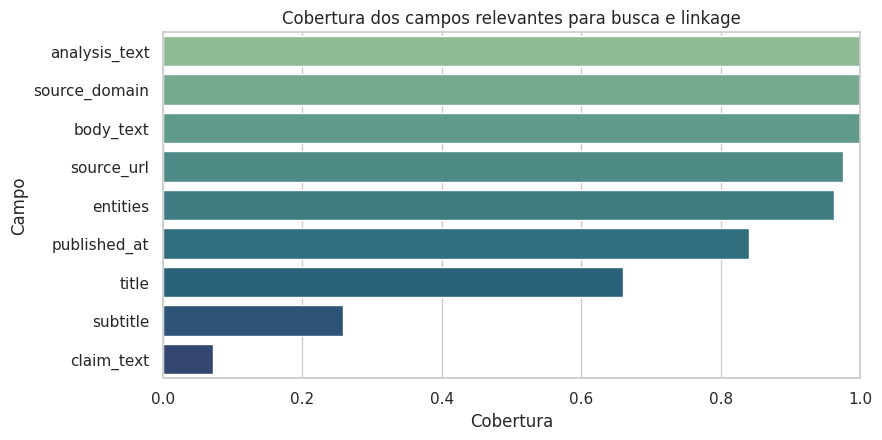

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=coverage_df, x='coverage_pct', y='field', palette='crest', ax=ax)
ax.set_title('Cobertura dos campos relevantes para busca e linkage')
ax.set_xlabel('Cobertura')
ax.set_ylabel('Campo')
ax.set_xlim(0, 1)
plt.show()


## 2. Qualidade de `title` como parâmetro de busca no recorte `mercado`

Aqui medimos proxies internos apenas sobre os registros `mercado` já deduplicados. Isso evita que títulos de `outros` ou itens repetidos distorçam a leitura sobre o valor real de `title` para busca.


In [5]:
duplicate_title_rows = sum(count for count in title_frequency.values() if count > 1)
duplicate_title_groups = sum(1 for count in title_frequency.values() if count > 1)
title_quality_snapshot = pd.DataFrame(
    [
        {'metric': 'rows_total', 'value': coverage_counter['rows']},
        {'metric': 'title_present', 'value': coverage_counter['title_present']},
        {'metric': 'title_duplicate_groups', 'value': duplicate_title_groups},
        {'metric': 'rows_in_duplicate_titles', 'value': duplicate_title_rows},
        {'metric': 'publisher_suffix_hits', 'value': sum(suffix_counter.values())},
        {'metric': 'boilerplate_prefix_hits', 'value': sum(prefix_counter.values())},
    ]
)
title_quality_snapshot


,metric,value
0,rows_total,1878
1,title_present,1239
2,title_duplicate_groups,38
3,rows_in_duplicate_titles,111
4,publisher_suffix_hits,113
5,boilerplate_prefix_hits,84


In [6]:
pd.DataFrame(title_frequency.most_common(15), columns=['title', 'frequency'])


,title,frequency
0,#Verificamos: sete boatos e dois fatos sobre a reforma da previdência em redes sociais,8
1,"#Verificamos: Publicação lista 31 ações de Bolsonaro em três meses, mas só sete são verdadeiras",7
2,Checamos os economistas dos 5 principais candidatos - Agência Pública,6
3,Exageros e imprecisões marcam discurso de Lula em caravana - Agência Pública,5
4,"Alckmin acerta evolução do PIB, mas usa dado falso sobre impostos - Agência Pública",5
5,6 blefes e meias-verdades sobre o pré-sal - Agência Pública,4
6,Checamos 4 argumentos dos senadores sobre a PEC dos gastos e contas públicas - Agência Pública,4
7,Imagem sobre trajetória de Pedro Parente faz acusações falsas - Agência Pública,4
8,5 frases dos candidatos a presidente sobre economia - Agência Pública,4
9,Meirelles defende governo Temer com dados falsos e distorção - Agência Pública,4


In [7]:
pd.DataFrame(domain_counter.most_common(15), columns=['source_domain', 'rows'])


,source_domain,rows
0,g1.globo.com,586
1,www.boatos.org,369
2,economia.uol.com.br,241
3,noticias.uol.com.br,172
4,apublica.org,104
5,www.diariodobrasil.org,92
6,www.uol.com.br,49
7,fake_whatsapp_br,43
8,economia.estadao.com.br,40
9,piaui.folha.uol.com.br,28


## 3. Construção de seeds e manifest de queries para `mercado`

Agora saímos do diagnóstico e geramos os artefatos reutilizáveis apenas para o recorte `mercado` sem duplicatas. Cada linha do seed catálogo representa uma notícia preparada para linkage, e cada linha do manifest representa uma consulta candidata já vinculada a `record_id`.


In [ ]:
seed_rows, query_rows = prepare_news_query_data(filtered_df.to_dict(orient='records'))
seed_df = pd.DataFrame(seed_rows)
query_df = pd.DataFrame(query_rows)

seed_df.head(3)


,record_id,dataset_id,published_at,title,title_clean,subtitle_clean,claim_or_lead_clean,top_entities,seed_reference_text,title_quality_band,title_had_boilerplate_prefix,title_had_publisher_suffix,source_url,source_domain,source_domain_display,language,catalogacao_final,veracidade_binaria,entity_count,has_source_url
0,factck_br:6f77ee663fe07670,factck_br,2016-11-18,5 deslizes de Temer ao falar do Congresso no Roda Viva - Agência Pública,5 deslizes de Temer ao falar do Congresso no Roda Viva,,"18 de novembro de 2016 Maurício Moraes, tore Medeiros, Patrícia Cagni Entre os vários temas abordados na entrevista ao programa Roda Viva, da TV Cultura, no...","[Maurício Moraes, tore Medeiros, Patrícia Cagni]","5 deslizes de Temer ao falar do Congresso no Roda Viva 18 de novembro de 2016 Maurício Moraes, tore Medeiros, Patrícia Cagni Entre os vários temas abordados...",strong,False,True,https://apublica.org/2016/11/truco-5-deslizes-de-temer-ao-falar-do-congresso-no-roda-viva/,apublica.org,apublica.org,pt-BR,mercado,sem_sinal,97,True
1,factck_br:f1275abf4b16dd78,factck_br,2016-11-18,5 deslizes de Temer ao falar do Congresso no Roda Viva - Agência Pública,5 deslizes de Temer ao falar do Congresso no Roda Viva,,"18 de novembro de 2016 Maurício Moraes, tore Medeiros, Patrícia Cagni Entre os vários temas abordados na entrevista ao programa Roda Viva, da TV Cultura, no...","[Maurício Moraes, tore Medeiros, Patrícia Cagni]","5 deslizes de Temer ao falar do Congresso no Roda Viva 18 de novembro de 2016 Maurício Moraes, tore Medeiros, Patrícia Cagni Entre os vários temas abordados...",strong,False,True,https://apublica.org/2016/11/truco-5-deslizes-de-temer-ao-falar-do-congresso-no-roda-viva/,apublica.org,apublica.org,pt-BR,mercado,sem_sinal,64,True
2,factck_br:a9335d3964836061,factck_br,2016-04-14,Checamos 12 argumentos pró e contra o impeachment - Agência Pública,12 argumentos pró e contra o impeachment,,"Verificamos frases ditas na comissão especial da Câmara pelos juristas Miguel Reale Júnior e Janaína Paschoal, autores do pedido, e pelo ministro da Advocac...","[Câmara, Miguel Reale Júnior, Janaína Paschoal]","12 argumentos pró e contra o impeachment Verificamos frases ditas na comissão especial da Câmara pelos juristas Miguel Reale Júnior e Janaína Paschoal, auto...",medium,True,True,https://apublica.org/2016/04/truco-checamos-12-argumentos-pro-e-contra-o-impeachment/,apublica.org,apublica.org,pt-BR,mercado,sem_sinal,43,True


In [9]:
query_df.head(5)


,query_id,record_id,dataset_id,query_priority,query_rank_for_record,query_strategy,query_text,origin_value,published_after,region_code,search_type,max_results,max_pages,title_quality_band,top_entities,seed_reference_text,should_run_by_default
0,qry-a31349b5013ea5a8,factck_br:6f77ee663fe07670,factck_br,1,1,title_core,5 deslizes Temer falar Congresso Roda Viva,rid=factck_br:6f77ee663fe07670|qid=qry-a31349b5013ea5a8|strategy=title_core,2016-11-04T00:00:00Z,BR,video,25,1,strong,"[Maurício Moraes, tore Medeiros, Patrícia Cagni]","5 deslizes de Temer ao falar do Congresso no Roda Viva 18 de novembro de 2016 Maurício Moraes, tore Medeiros, Patrícia Cagni Entre os vários temas abordados...",True
1,qry-8aaacfa99ed13697,factck_br:f1275abf4b16dd78,factck_br,1,1,title_core,5 deslizes Temer falar Congresso Roda Viva,rid=factck_br:f1275abf4b16dd78|qid=qry-8aaacfa99ed13697|strategy=title_core,2016-11-04T00:00:00Z,BR,video,25,1,strong,"[Maurício Moraes, tore Medeiros, Patrícia Cagni]","5 deslizes de Temer ao falar do Congresso no Roda Viva 18 de novembro de 2016 Maurício Moraes, tore Medeiros, Patrícia Cagni Entre os vários temas abordados...",True
2,qry-3ef902b0dcf424e9,factck_br:a9335d3964836061,factck_br,1,1,title_core,12 argumentos pró impeachment,rid=factck_br:a9335d3964836061|qid=qry-3ef902b0dcf424e9|strategy=title_core,2016-03-31T00:00:00Z,BR,video,25,1,medium,"[Câmara, Miguel Reale Júnior, Janaína Paschoal]","12 argumentos pró e contra o impeachment Verificamos frases ditas na comissão especial da Câmara pelos juristas Miguel Reale Júnior e Janaína Paschoal, auto...",True
3,qry-f87d1609e78d54a0,factck_br:a9335d3964836061,factck_br,2,2,title_plus_entities,12 argumentos pró impeachment Câmara Miguel Reale Júnior,rid=factck_br:a9335d3964836061|qid=qry-f87d1609e78d54a0|strategy=title_plus_entities,2016-03-15T00:00:00Z,BR,video,25,1,medium,"[Câmara, Miguel Reale Júnior, Janaína Paschoal]","12 argumentos pró e contra o impeachment Verificamos frases ditas na comissão especial da Câmara pelos juristas Miguel Reale Júnior e Janaína Paschoal, auto...",True
4,qry-d50793902e514804,factck_br:adcd28005b8e8a20,factck_br,1,1,title_core,12 argumentos pró impeachment,rid=factck_br:adcd28005b8e8a20|qid=qry-d50793902e514804|strategy=title_core,2016-03-31T00:00:00Z,BR,video,25,1,medium,"[Plano Safra, Ministério da Fazenda, Banco do Brasil]",12 argumentos pró e contra o impeachment Todo o foco da denúncia diz respeito à situação de relação jurídica decorrente do chamado Plano Safra. O Plano Safr...,True


In [10]:
seed_df['title_quality_band'].value_counts(dropna=False).rename_axis('title_quality_band').reset_index(name='records')


,title_quality_band,records
0,strong,1155
1,missing,639
2,medium,82
3,weak,2


/tmp/ipykernel_448141/2412097240.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=seed_df, x='title_quality_band', order=['strong', 'medium', 'weak', 'missing'], palette='mako', ax=ax)


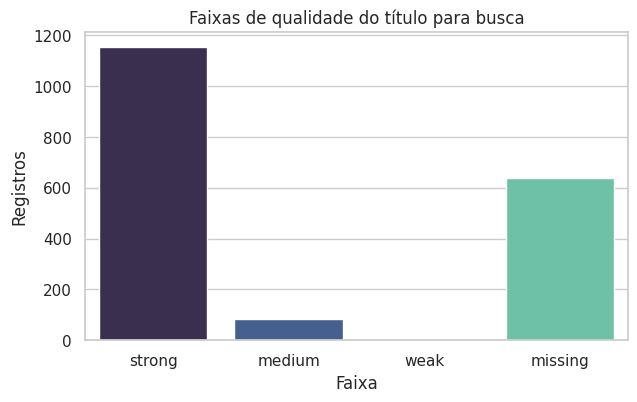

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=seed_df, x='title_quality_band', order=['strong', 'medium', 'weak', 'missing'], palette='mako', ax=ax)
ax.set_title('Faixas de qualidade do título para busca')
ax.set_xlabel('Faixa')
ax.set_ylabel('Registros')
plt.show()


In [12]:
query_strategy_summary = (
    query_df.groupby(['title_quality_band', 'query_strategy'])
    .size()
    .rename('queries')
    .reset_index()
)
query_strategy_summary


,title_quality_band,query_strategy,queries
0,medium,title_core,82
1,medium,title_plus_entities,82
2,missing,lead_plus_entities,639
3,strong,title_core,1155
4,weak,lead_plus_entities,2
5,weak,title_plus_entities,2


In [13]:
examples_by_band = (
    seed_df[['record_id', 'title', 'title_clean', 'title_quality_band', 'top_entities', 'claim_or_lead_clean']]
    .sort_values(['title_quality_band', 'record_id'])
    .groupby('title_quality_band', group_keys=False)
    .head(5)
)
examples_by_band


,record_id,title,title_clean,title_quality_band,top_entities,claim_or_lead_clean
274,factck_br:004ff5e7afeb1212,Checamos os economistas dos 5 principais candidatos - Agência Pública,os economistas dos 5 principais candidatos,medium,[],Boa parte do desemprego está nas cidades e no setor da construção civil.
280,factck_br:068dbadc297280ed,"#Verificamos: Publicação lista 31 ações de Bolsonaro em três meses, mas só sete são verdadeiras","Publicação lista 31 ações de Bolsonaro em três meses, mas só sete são verdadeiras",medium,[],Criou a PEC da Previdência
269,factck_br:188e83edde957258,#Verificamos: INSS não pagou 'indenização de R$ 750 mil à família de ladrão morto por mãe-PM',INSS não pagou 'indenização de R$ 750 mil à família de ladrão morto por mãe-PM',medium,[],INSS determina indenização de R$ 750 mil à família de ladrão morto por uma mãe PM
64,factck_br:276785c4fb9979a7,"#Verificamos: Publicação lista 31 ações de Bolsonaro em três meses, mas só sete são verdadeiras","Publicação lista 31 ações de Bolsonaro em três meses, mas só sete são verdadeiras",medium,[],"Gerou saldo positivo nas contas do governo de R$ 30,2 bilhões em 3 meses"
256,factck_br:2ec3409c10426ffe,#Verificamos: sete boatos e dois fatos sobre a reforma da previdência em redes sociais,sete boatos e dois fatos sobre a reforma da previdência em redes sociais,medium,[Reforma da Previdência],"... Reforma da Previdência: homens - 65 anos, mulheres - 62 anos"
527,fake_br:full_texts:fake:1124,,,missing,"[Associação dos Criadores de Gado, Trump, JBS]",Associação dos Criadores de Gado envia carta para Trump e pede o bloqueio dos bens da JBS nos EUA
128,fake_br:full_texts:fake:1185,,,missing,"[Família de Mendes, Joesley, JBS]","Família de Mendes vendia gado para Joesley: ""Vendemos gado para a JBS no Mato Grosso"""
562,fake_br:full_texts:fake:1190,,,missing,"[MPF, JBS, Joesley]","MPF calcula que JBS foi ""agraciada"" com R$ 45 bilhões dos cofres públicos"
516,fake_br:full_texts:fake:1210,,,missing,"[JBS, Lula, Dilma]",Faturamento da JBS saltou de R$ 4 bi para R$ 170 bi durante governos Lula e Dilma
615,fake_br:full_texts:fake:1249,,,missing,"[Stratfor, George Friedman, Business Insider]","Empresa de inteligência americana alerta: ""O mundo deve estar preparado para uma nova guerra"""


In [14]:
artifact_paths = write_prepared_artifacts(
    seed_rows=seed_rows,
    query_rows=query_rows,
    output_dir=OUTPUT_DIR,
)
artifact_paths


{'seed_jsonl': 'data/processed/news_query_preparation_market_only/news_seed_catalog.jsonl',
 'seed_parquet': 'data/processed/news_query_preparation_market_only/news_seed_catalog.parquet',
 'query_jsonl': 'data/processed/news_query_preparation_market_only/news_query_manifest.jsonl',
 'query_parquet': 'data/processed/news_query_preparation_market_only/news_query_manifest.parquet'}

## 4. Leitura operacional dos resultados

Leitura sugerida para o pipeline no recorte `mercado`:
- `strong`: o título limpo pode ser usado como consulta principal;
- `medium`: o título já é útil, mas ganha robustez quando combinado com entidades;
- `weak` e `missing`: a busca depende de lead textual, entidades e janela temporal;
- `origin_value` mantém a trilha até `record_id` sem mudar o contrato do client.

Conclusão prática: neste notebook, itens `outros` são ignorados e duplicatas são dispensadas antes da preparação. O `title` só é tratado como bom parâmetro principal quando passa limpo pelas heurísticas e cai em `strong`; no restante do recorte `mercado`, a melhor estratégia é consultar o YouTube com queries compostas e já preparadas para linkage.


## 5. Exemplo de uso futuro com o client

A célula abaixo é apenas demonstrativa. Ela mantém o uso do `YouTubeDataClient` igual ao projeto atual e usa `origin_value` para preservar o vínculo com `record_id`.


In [15]:
RUN_SAMPLE_API_CALL = False

if RUN_SAMPLE_API_CALL:
    from youtube_data_pipeline import YouTubeDataClient, YouTubeDataConfig

    config = YouTubeDataConfig(
        api_key='YOUR_API_KEY',
        storage_root='../data/raw',
        run_id='news-query-demo',
    )
    client = YouTubeDataClient.from_config(config)

    for query_row in query_rows[:5]:
        client.fetch(
            'search',
            {
                'part': 'snippet',
                'q': query_row['query_text'],
                'type': query_row['search_type'],
                'maxResults': query_row['max_results'],
                'publishedAfter': query_row['published_after'],
                'regionCode': query_row['region_code'],
            },
            max_pages=query_row['max_pages'],
            origin=query_row['origin_value'],
        )
